In [1]:
import numpy as np
import matplotlib as plt


Task 1 - Trace a small MLP

In [2]:
X = np.array([[1.,0.], [0.,1.], [1.,1.]])
y = np.array([[1.],[2.],[1.]])
W1 = np.array([[1.,-1.],[-1.,1.]])
b1 = np.array([0.5,0.5])
W2 = np.array([[1.],[2.]])
b2 = np.array([0.])
Z1 = np.dot(X,W1) + b1
H = np.maximum(Z1,0)
Yhat = np.dot(H,W2) + b2

1. Draw the architecture by hand on paper; take a picture and include it in your notebook when you submit. State the number of hidden layers/units and count all trainable weights and biases, including zeros.

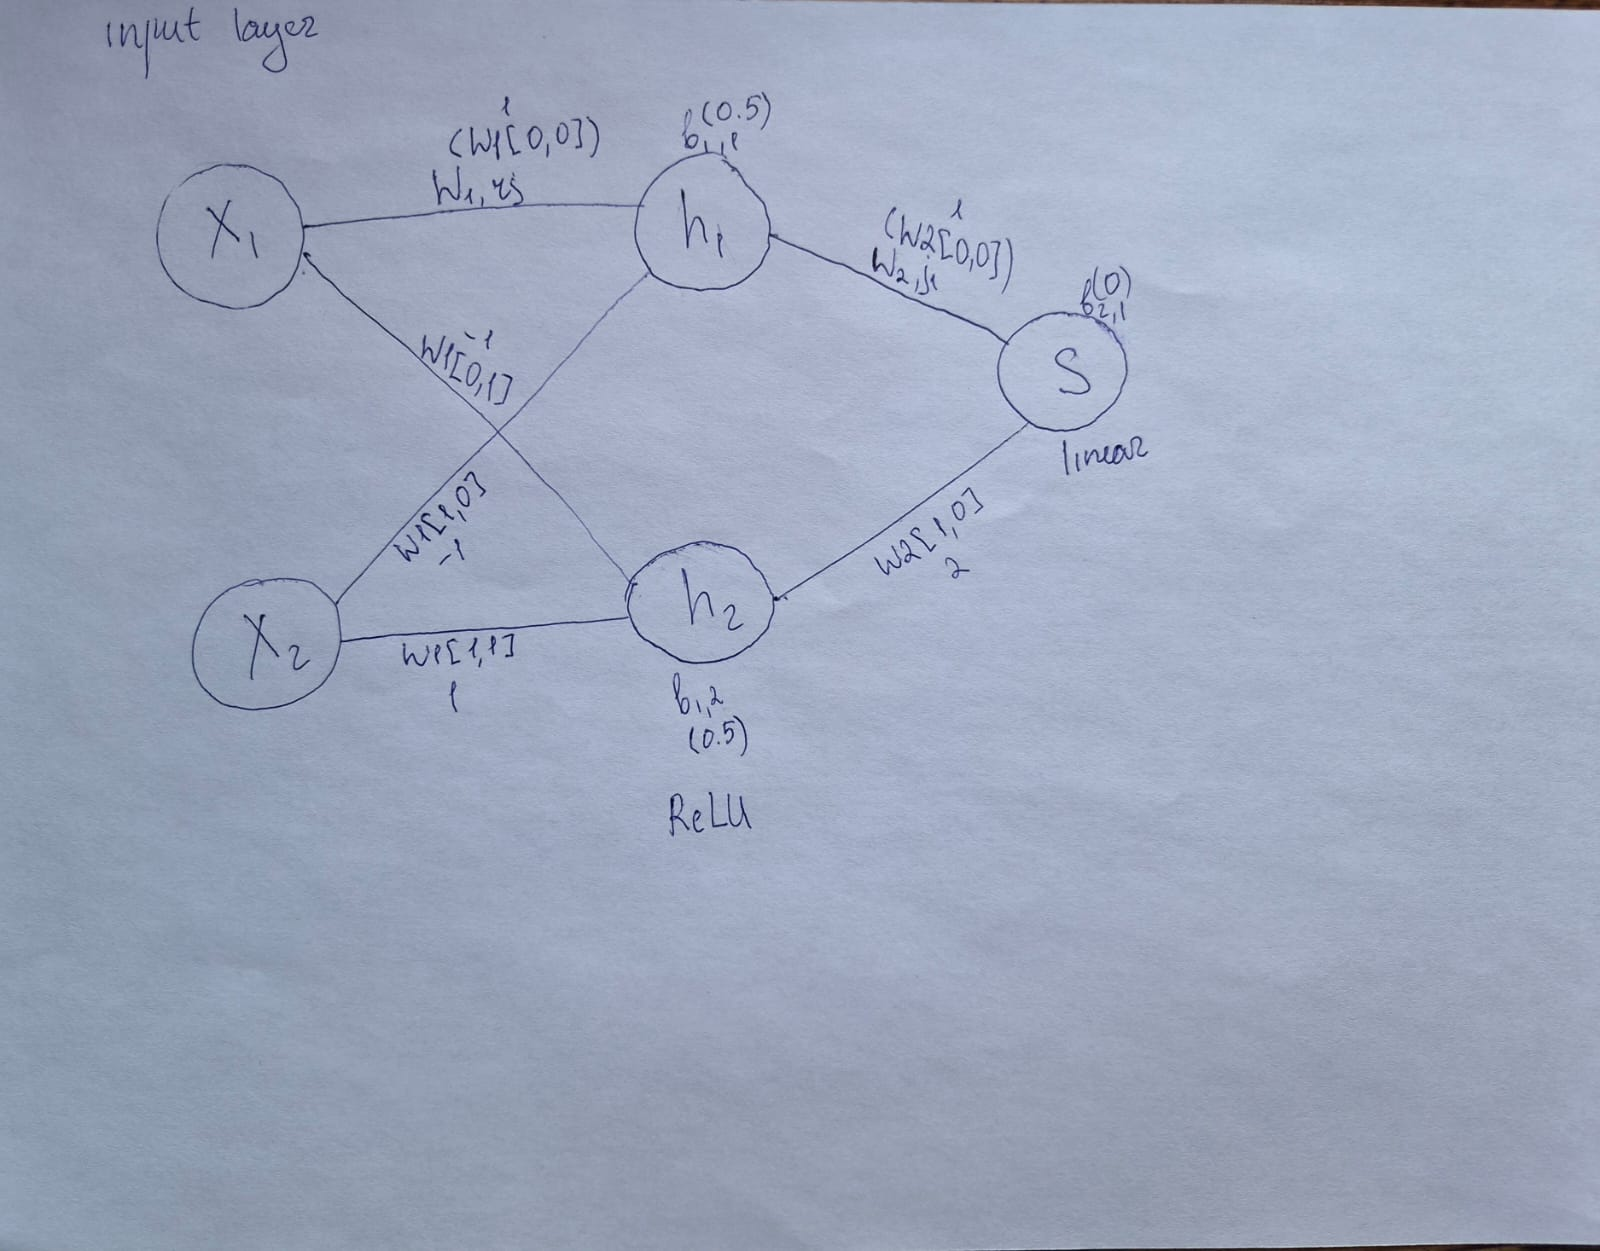

State the number of hidden layers/units and count all trainable weights and biases, including zeros

number of hidden layers is one and 2 hidden units

number of:

W1 = 2 * 2 = 4

b1 = 2

W2 = 2 * 1 = 2

b2 = 1

Number of all parameters is 9

2. Give the shapes of X, y, W1, b1, Z1, H, W2, b2, Yhat

In [ ]:
print(X.shape)
print(y.shape)
print(W1.shape)
print(b1.shape)
print(W2.shape)
print(b2.shape)
print(Z1.shape)
print(H.shape)
print(Yhat.shape)

(3, 2)
(3, 1)
(2, 2)
(2,)
(2, 1)
(1,)
(3, 2)
(3, 2)
(3, 1)


3. Compute Z1, H, and Yhat by hand for every row; add targets, squared errors, and mean losss to your table

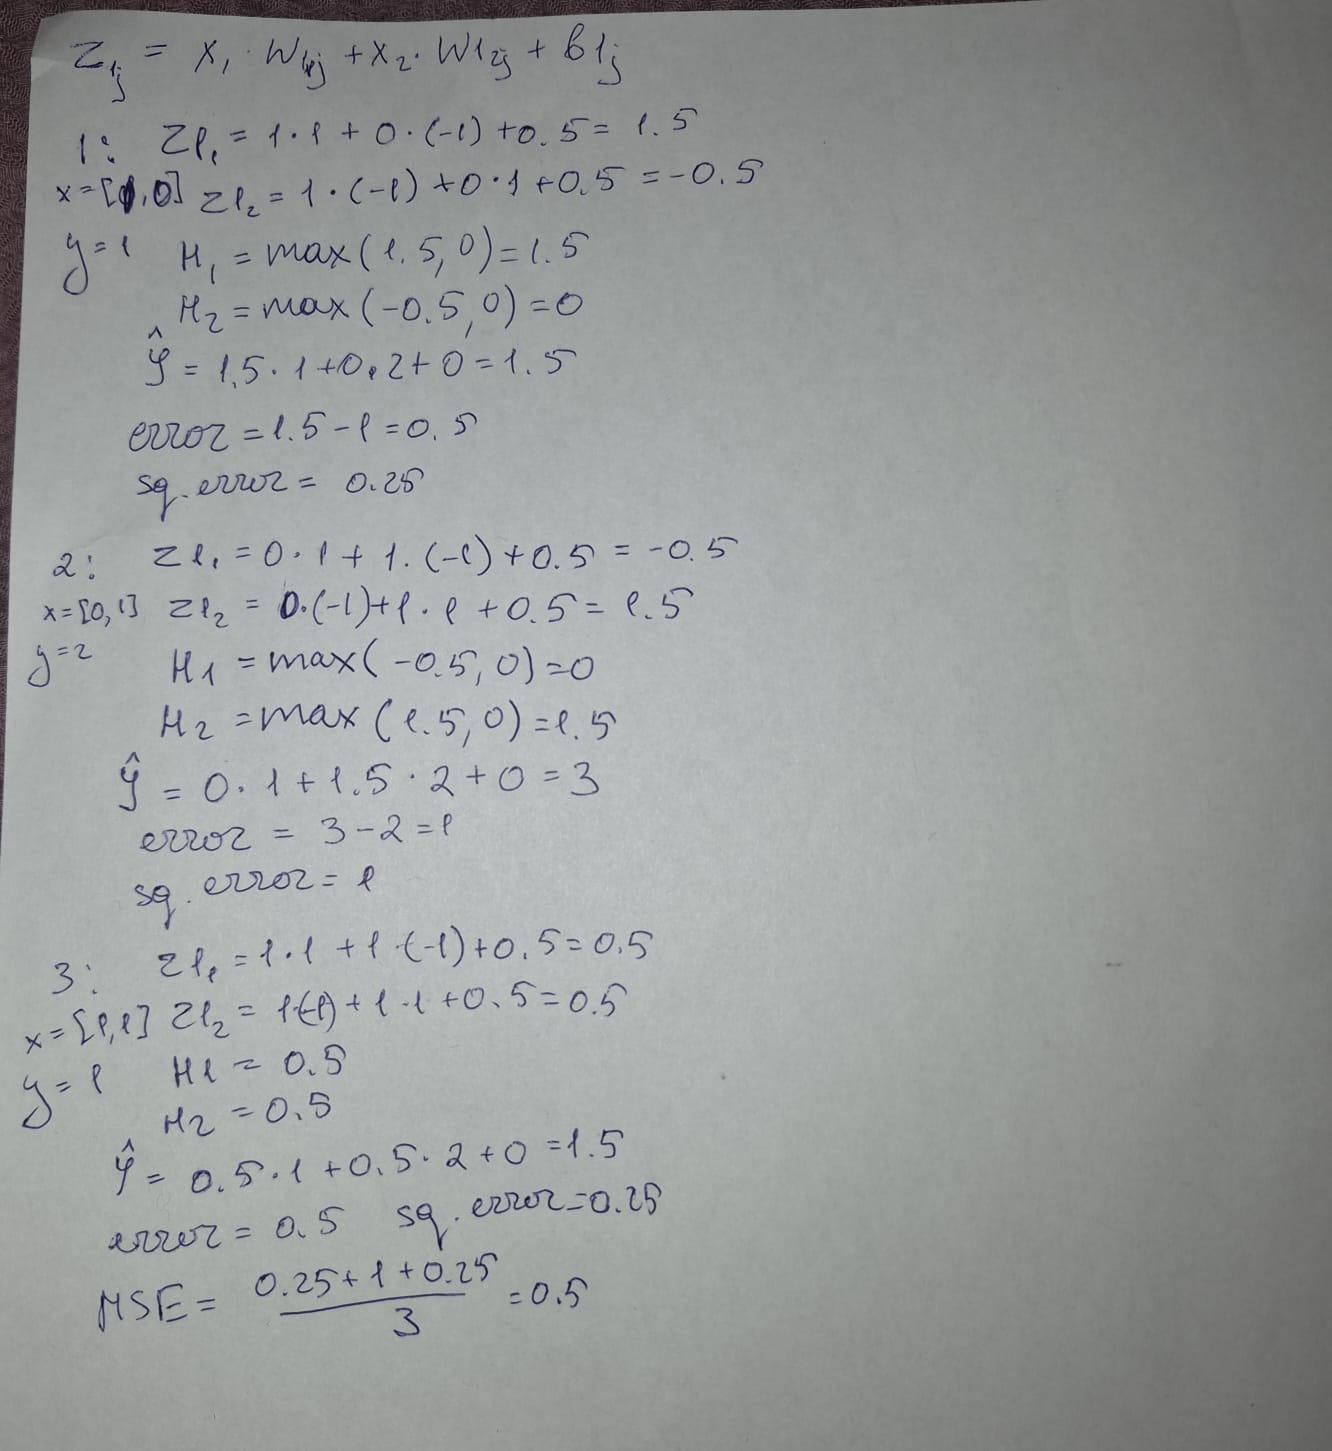

4. Verify in NumPy. Assert Yhat.shape == y.shape before computing residuals

In [4]:
assert Yhat.shape == y.shape
residuals = Yhat - y
print(residuals)

[[0.5]
 [1. ]
 [0.5]]


5. Remove only ReLU, keeping parameters fixed; recompute and explain why the result is affine.

In [6]:
Yhat_without_ReLU = Z1 @ W2 + b2
print(Yhat_without_ReLU)

[[0.5]
 [2.5]
 [1.5]]


the result is affine because our neuron has a simple linear function

6. Explain why all rows share the same parameters, and why parameter count doesn't depend on the number of examples
Because we apply  the same weights and biases to all rows. So number of our parameters (weights and biases) doesn't depend on number of examples

sanity check: row 1's hidden pre-activations are [1.5,-0.5] not its activations. do not train the network in this task

In [ ]:
print(Z1[0])

[ 1.5 -0.5]


Task 2 - Choose and compare losses

A. Regression

In [ ]:
y = np.array([1, 2, 4])
y_pred = np.array([0, 2, 7])

residuals = y_pred - y
MSE = np.mean((y_pred - y)**2)
MAE = np.mean(np.abs(y_pred - y))

print(residuals)
print(MSE, MAE)

[-1  0  3]
3.3333333333333335 1.3333333333333333


In [ ]:
y_pred2 = np.array([0, 2, 10])

residuals2 = y_pred2 - y
MSE2 = np.mean(residuals2**2)
MAE2 = np.mean(np.abs(residuals2))

print(residuals2)
print(MSE2, MAE2)

[-1  0  6]
12.333333333333334 2.3333333333333335


Explain the difference in sensitivity to the larger error - the two losses use different scales, so a smaller numeric value doesn't automatically mean "better"

The MSE is increased more because it's quadratic while MAE linear. So MSE punishes more severely

B. Binary classification

For each model: mean BCE, predicted classes at threshold p > 0.5, and accuracy. Explain how the accuracies can agree while the BCE values differ. Don't feed thresholded classes into BCE.

In [ ]:
y = np.array([1,0])
a_pred = np.array([0.8,0.2])
b_pred = np.array([0.6,0.4])
L_a = -np.mean(y*np.log(a_pred) + (1-y)*np.log(1-a_pred))
L_b = -np.mean(y*np.log(b_pred) + (1-y)*np.log(1-b_pred))
print(L_a, L_b)
a_class = (a_pred > 0.5).astype(int)
b_class = (b_pred > 0.5).astype(int)
print(a_class, b_class)
accuracy_a = np.mean(a_class == y)
accuracy_b = np.mean(b_class == y)
print(accuracy_a, accuracy_b)

0.2231435513142097 0.5108256237659907
[1 0] [1 0]
1.0 1.0


Accuracies agree while BCE not because accuracies checks if predicted classes with the given threshold match with y. And for BCE we use probabilities of the class 1 which is more precise and different for two models

C. Multiclass

In [ ]:
logits = [0, np.log(3), 0]
p = [np.exp(x)/np.sum(np.exp(logits)) for x in logits]
print(p)
sum = np.sum(p)
print(sum)
l = -np.log(p[1])
print(l)

[np.float64(0.2), np.float64(0.6000000000000001), np.float64(0.2)]
1.0
0.5108256237659905


Then, one sentence each: an output representation + loss for (a) an unrestricted real value, (b) a yes/no outcome, (c) exactly one of three categories.

(a)Softmax is an activation function that takes unrestricted raw numbers (logits) and transforms them into an output that lies between 0 and 1 and represents probability, the sum of all outputs equals 1.
Loss is negative log of probability of right class, so that it penalizes more if probability approaches 0 and smaller when it close to 1

(b)yes/ no outcome is when we have two samples and probabilities like 1 and 0

(c) because the sum of all the probabilities after softmax equals to 1, we could have one sample with the largest probability. for 3 categories we have three probabilities for each sample and their sum equals 1.



Task 3 - Train a two-hidden-unit MLP


A. Forward pass


In [8]:
X = np.array([[-2.],[-1.],[-0.5],[0.5],[1.],[2.]])
y = np.abs(X)
initials = {
    "W1":np.array([[0.5,-0.5]]),
    "b1":np.array([0.,0.]),
    "W2":np.array([[0.5],[0.5]]),
    "b2":np.array([0.])
}

def forward(params, X):
    Z1 = np.dot(X, params["W1"]) + params["b1"]
    H = np.maximum(Z1, 0)
    Yhat = np.dot(H, params["W2"]) + params["b2"]
    return Z1, H, Yhat

def mse(params, X, y):
    _, _, Yhat = forward(params, X)
    return np.mean((Yhat - y)**2)

Z1, H, Yhat = forward(initials, X)
L = mse(initials, X, y)

assert np.allclose(H[0], [0, 1]), f"H mismatch at x=-2: got {H[0]}"
assert np.isclose(Yhat[0], 0.5), f"Yhat mismatch at x=-2: got {Yhat[0]}"

print(Z1)
print(H)
print(Yhat)
print(L)


[[-1.    1.  ]
 [-0.5   0.5 ]
 [-0.25  0.25]
 [ 0.25 -0.25]
 [ 0.5  -0.5 ]
 [ 1.   -1.  ]]
[[0.   1.  ]
 [0.   0.5 ]
 [0.   0.25]
 [0.25 0.  ]
 [0.5  0.  ]
 [1.   0.  ]]
[[0.5  ]
 [0.25 ]
 [0.125]
 [0.125]
 [0.25 ]
 [0.5  ]]
0.984375


B. Backward pass

In [9]:
def gradients(params, X, y)-> dict:
  W1, b1, W2, b2 = params['W1'], params['b1'], params['W2'], params['b2']
  N = X.shape[0]
  Z1, H, Yhat = forward(params, X)
  G = (2 / N) * (Yhat - y)
  dW2 = H.T @ G
  db2 = np.sum(G, axis=0)
  D = (G @ W2.T) * (Z1 > 0)
  dW1 = X.T @ D
  db1 = np.sum(D, axis=0)
  return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}
print(gradients(initials, X, y))


{'W1': array([[-0.65625,  0.65625]]), 'b1': array([-0.4375, -0.4375]), 'W2': array([[-0.65625],
       [-0.65625]]), 'b2': array([-1.75])}


C. Run the experiment

In [11]:
params = {name: value.copy() for name, value in initials.items()}
grads0 = gradients(params, X, y)
for name in params:
    print(f"{name}: grad shape {grads0[name].shape}, param shape {params[name].shape}")
    assert grads0[name].shape == params[name].shape

W1: grad shape (1, 2), param shape (1, 2)
b1: grad shape (2,), param shape (2,)
W2: grad shape (2, 1), param shape (2, 1)
b2: grad shape (1,), param shape (1,)


In [12]:
old_loss = mse(params, X, y)
grads = gradients(params, X, y)
params = {name: params[name] - 0.05 * grads[name] for name in params}
new_loss = mse(params, X, y)
print("Loss before:", old_loss, "Loss after one step:", new_loss)

Loss before: 0.984375 Loss after one step: 0.7415765000805258


In [13]:
from os import name
params = {name: value.copy() for name, value in initials.items()}
history = [mse(params, X, y)]
for step in range(300):
  grads = gradients(params, X, y)
  params = {
      name: params[name] - 0.05 * grads[name]
      for name in params
  }
  history.append(mse(params, X, y))
print(len(history))

301


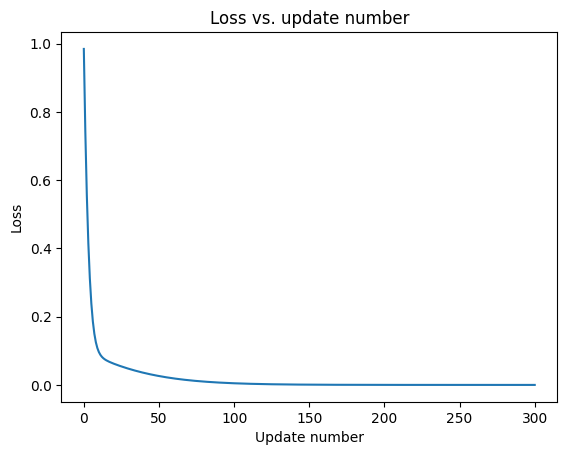

Final predictions: [[1.99845228]
 [1.00078542]
 [0.50195199]
 [0.50195199]
 [1.00078542]
 [1.99845228]]
Final MSE: 2.274200788567709e-06
Lower than initial? True


In [15]:
plt.plot(range(301), history)
plt.xlabel("Update number")
plt.ylabel("Loss")
plt.title("Loss vs. update number")
plt.show()

_, _, Yhat_final = forward(params, X)
final_mse = mse(params, X, y)
print("Final predictions:", Yhat_final)
print("Final MSE:", final_mse)
print("Lower than initial?", final_mse < history[0])

Predictions on X_check: [[1.49961885]
 [0.75136871]
 [0.75136871]
 [1.49961885]]
MSE on X_check: 1.0093159510004993e-06


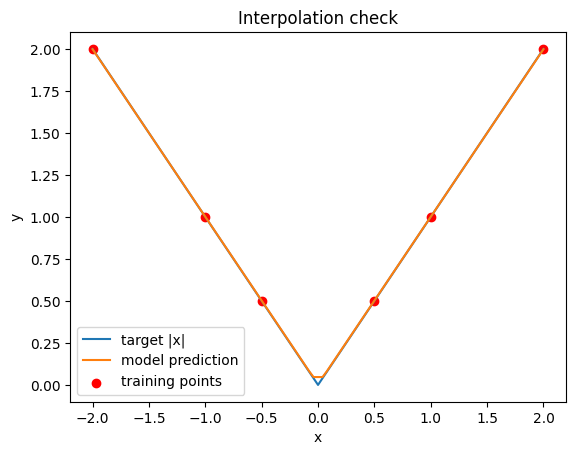

In [16]:
X_check = np.array([[-1.5],[-0.75],[0.75],[1.5]])
y_check = np.abs(X_check)
_, _, Yhat_check = forward(params, X_check)
mse_check = mse(params, X_check, y_check)
print("Predictions on X_check:", Yhat_check)
print("MSE on X_check:", mse_check)

X_grid = np.linspace(-2, 2, 101).reshape(-1, 1)
_, _, Yhat_grid = forward(params, X_grid)

plt.plot(X_grid, np.abs(X_grid), label="target |x|")
plt.plot(X_grid, Yhat_grid, label="model prediction")
plt.scatter(X, y, color="red", label="training points")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpolation check")
plt.show()